In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [7]:
data = pd.read_csv("../other/Time-Wasters on Social Media.csv")
df = pd.DataFrame(data)

df = df.drop(['UserID','Location','Profession','Demographics', 'Platform','Video Category','Frequency','Watch Reason','DeviceType','OS','Watch Time','CurrentActivity','ConnectionType','Video ID'], axis=1)
df.tail()

,Age,Gender,Income,Debt,Owns Property,Total Time Spent,Number of Sessions,Video Length,Engagement,Importance Score,Time Spent On Video,Number of Videos Watched,Scroll Rate,ProductivityLoss,Satisfaction,Self Control,Addiction Level
995,22,Male,74254,True,True,144,7,1,5179,6,17,17,47,9,1,10,0
996,40,Female,27006,False,False,231,15,2,1803,4,2,17,15,8,2,10,0
997,27,Male,94218,True,True,165,1,12,9290,3,9,28,44,9,1,10,0
998,61,Male,85344,True,False,151,11,15,2050,5,12,30,62,3,7,5,5
999,19,Male,53840,True,True,167,17,4,9790,3,19,40,6,6,4,8,2


In [8]:
df.describe()

,Age,Income,Total Time Spent,Number of Sessions,Video Length,Engagement,Importance Score,Time Spent On Video,Number of Videos Watched,Scroll Rate,ProductivityLoss,Satisfaction,Self Control,Addiction Level
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,40.986000,59524.213000,151.406000,10.013000,15.214000,4997.159000,5.129000,14.973000,25.248000,49.774000,5.136000,4.864000,7.094000,2.906000
std,13.497852,23736.212925,83.952637,5.380314,8.224953,2910.053701,2.582834,8.200092,14.029159,29.197798,2.122265,2.122265,2.058495,2.058495
min,18.000000,20138.000000,10.000000,1.000000,1.000000,15.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,0.000000
25%,29.000000,38675.250000,78.000000,6.000000,8.000000,2415.750000,3.000000,8.000000,14.000000,23.000000,3.000000,4.000000,5.000000,2.000000
50%,42.000000,58805.000000,152.000000,10.000000,15.000000,5016.000000,5.000000,15.000000,25.000000,50.000000,5.000000,5.000000,7.000000,3.000000
75%,52.000000,79792.250000,223.000000,15.000000,22.000000,7540.250000,7.000000,22.000000,37.000000,74.000000,6.000000,7.000000,8.000000,5.000000
max,64.000000,99676.000000,298.000000,19.000000,29.000000,9982.000000,9.000000,29.000000,49.000000,99.000000,9.000000,9.000000,10.000000,7.000000


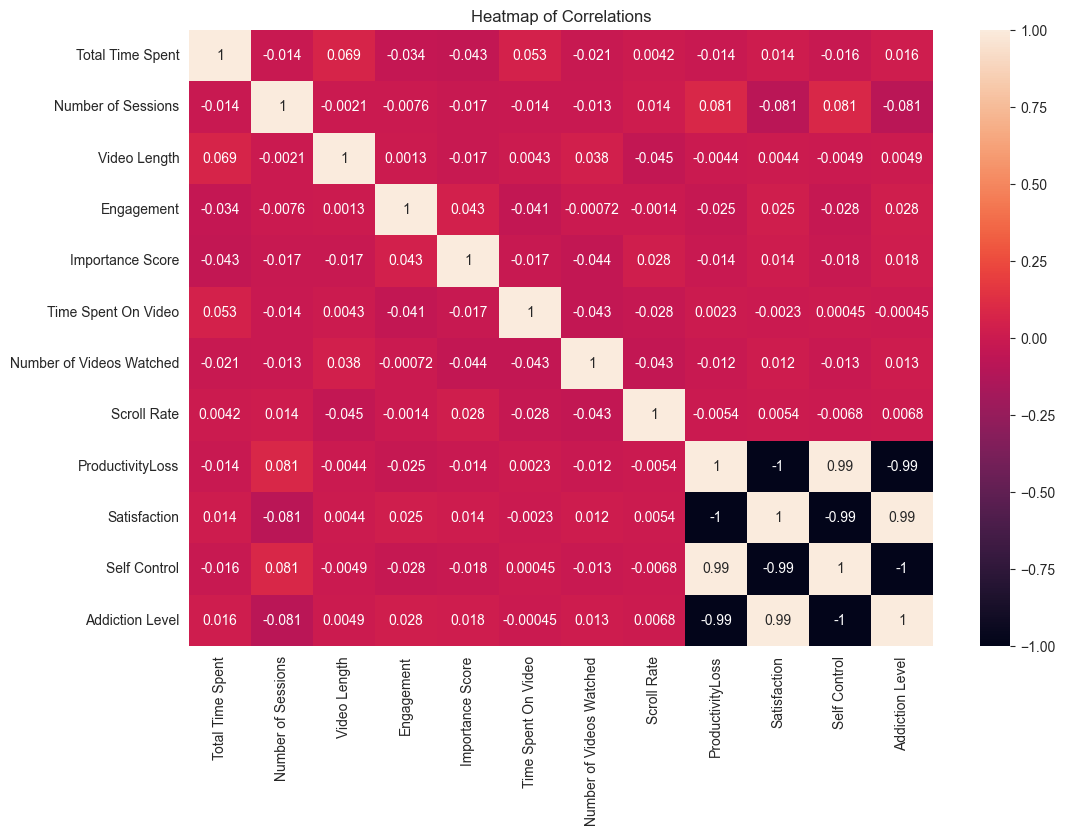

In [24]:
data_corr = df.drop(['Age','Income','Debt','Owns Property'], axis=1)
correlation_matrix = data_corr.corr(numeric_only=True)
plt.figure(figsize=(12, 8))

sns.heatmap(correlation_matrix, annot=True)

plt.title('Heatmap of Correlations')
plt.show()

In [25]:
print("\n-----CORRELATION (top pairs)-----")

corr_unstack = correlation_matrix.unstack().reset_index()
corr_unstack.columns = ['var1', 'var2', 'value']
corr_unstack = corr_unstack[corr_unstack['var1'] != corr_unstack['var2']]
corr_unstack['abs_value'] = corr_unstack['value'].abs()
corr_unstack = corr_unstack.sort_values('abs_value', ascending=False).drop_duplicates(subset=['value'])
display(corr_unstack.head(12))


-----CORRELATION (top pairs)-----


,var1,var2,value,abs_value
105,ProductivityLoss,Satisfaction,-1.000000,1.000000
141,Addiction Level,Satisfaction,0.994939,0.994939
140,Addiction Level,ProductivityLoss,-0.994939,0.994939
129,Self Control,Satisfaction,-0.994939,0.994939
106,ProductivityLoss,Self Control,0.994939,0.994939
21,Number of Sessions,Satisfaction,-0.081461,0.081461
20,Number of Sessions,ProductivityLoss,0.081461,0.081461
22,Number of Sessions,Self Control,0.080961,0.080961
133,Addiction Level,Number of Sessions,-0.080961,0.080961
24,Video Length,Total Time Spent,0.068607,0.068607


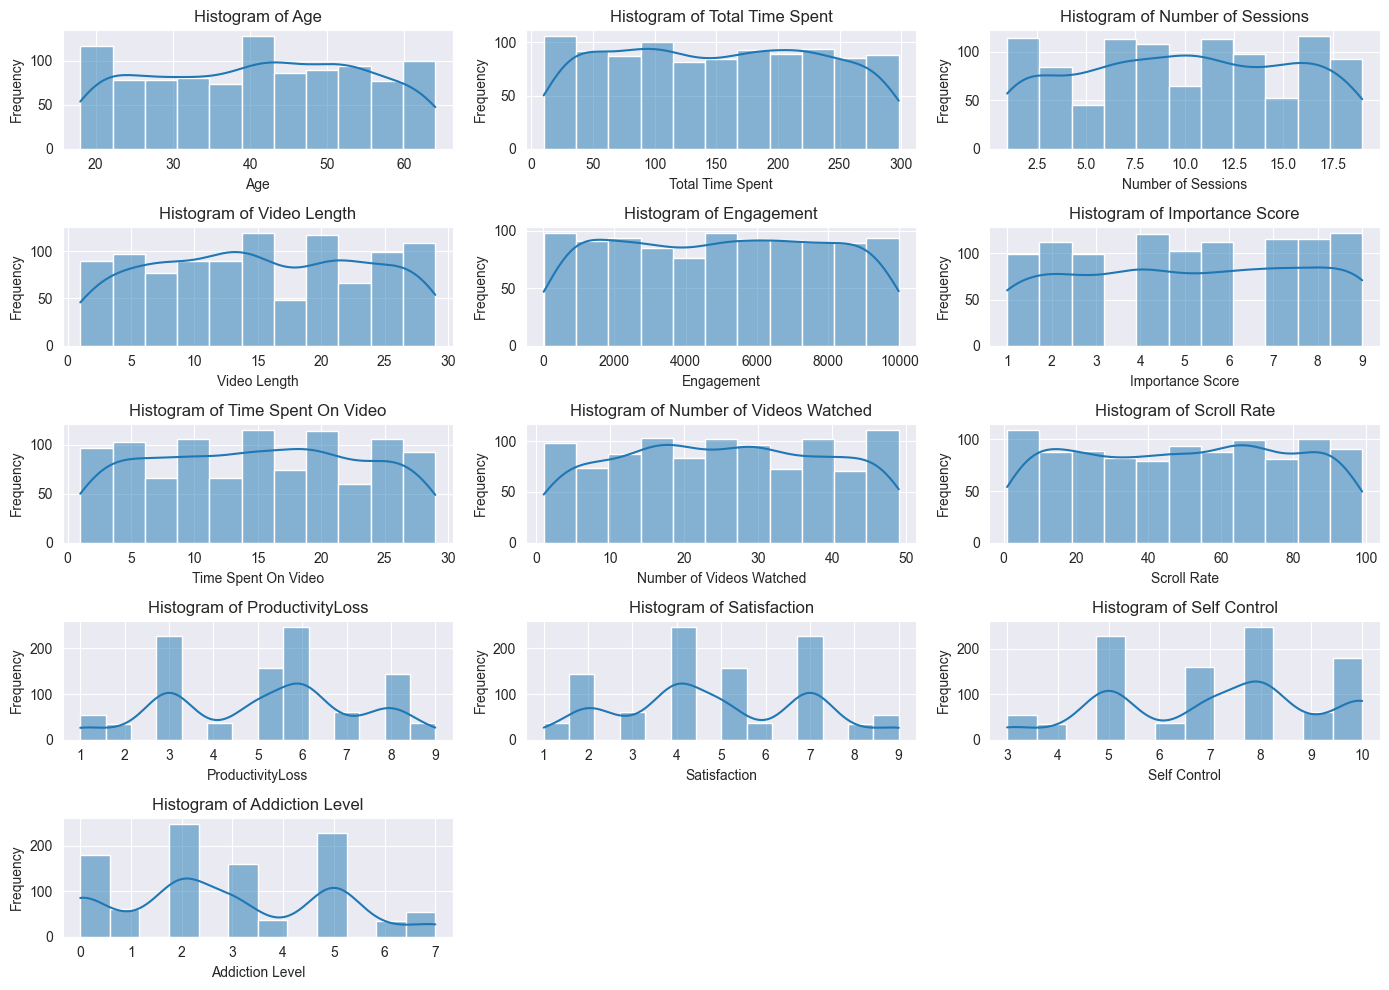

In [28]:
                       numeric_df = df.drop(['Gender','Income','Debt','Owns Property'],axis=1)
plt.figure(figsize= (14,10))

for i, feature in enumerate(numeric_df.columns):
    plt.subplot(5,3,i+1)
    #kde set to true so we can se the curve
    sns.histplot(numeric_df[feature], kde= True)
    plt.title(f'Histogram of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

plt.tight_layout() #for preventing overlap
plt.show()